In [34]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
import pandas as pd
import matplotlib.pyplot as plt

In [36]:
import pandas as pd

df = pd.read_csv("saccharification_process_data.csv")

In [37]:
df.shape
df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   initial_starch_concentration_g_L   5000 non-null   float64
 1   initial_dextrin_avg_dp             5000 non-null   float64
 2   saccharification_temp_C            5000 non-null   float64
 3   pH                                 5000 non-null   float64
 4   glucoamylase_activity_U_g          5000 non-null   float64
 5   glucoamylase_dosage_g_kg           5000 non-null   float64
 6   saccharification_duration_h        5000 non-null   float64
 7   water_to_substrate_ratio           5000 non-null   float64
 8   initial_glucose_concentration_g_L  5000 non-null   float64
 9   mixing_rate_rpm                    5000 non-null   float64
 10  glucose_yield_g_L                  5000 non-null   float64
dtypes: float64(11)
memory usage: 429.8 KB


In [38]:
df.describe()

,initial_starch_concentration_g_L,initial_dextrin_avg_dp,saccharification_temp_C,pH,glucoamylase_activity_U_g,glucoamylase_dosage_g_kg,saccharification_duration_h,water_to_substrate_ratio,initial_glucose_concentration_g_L,mixing_rate_rpm,glucose_yield_g_L
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,299.366398,8.897845,59.988477,4.510806,299.440977,1.244468,47.911453,2.999383,4.960128,199.985784,220.981892
std,57.926730,3.427398,4.928110,0.405446,57.201226,0.431350,13.786769,0.580888,4.988414,57.441463,124.311832
min,200.002327,3.000634,40.387999,3.045920,200.022046,0.500101,24.000266,2.000033,0.000468,100.020942,0.000022
25%,248.772561,5.965751,56.730005,4.235300,250.362104,0.867155,35.911509,2.500847,1.372364,150.179738,118.120475
50%,300.001725,8.831659,59.980941,4.513248,299.836328,1.241959,48.079814,2.994295,3.401651,200.964360,239.800562
75%,349.620173,11.800459,63.253711,4.786365,347.275249,1.618897,59.705368,3.510698,6.990997,248.705655,317.781238
max,399.943535,14.994062,76.888841,6.291634,399.919676,1.999598,71.989890,3.999781,52.442915,299.968260,450.191804


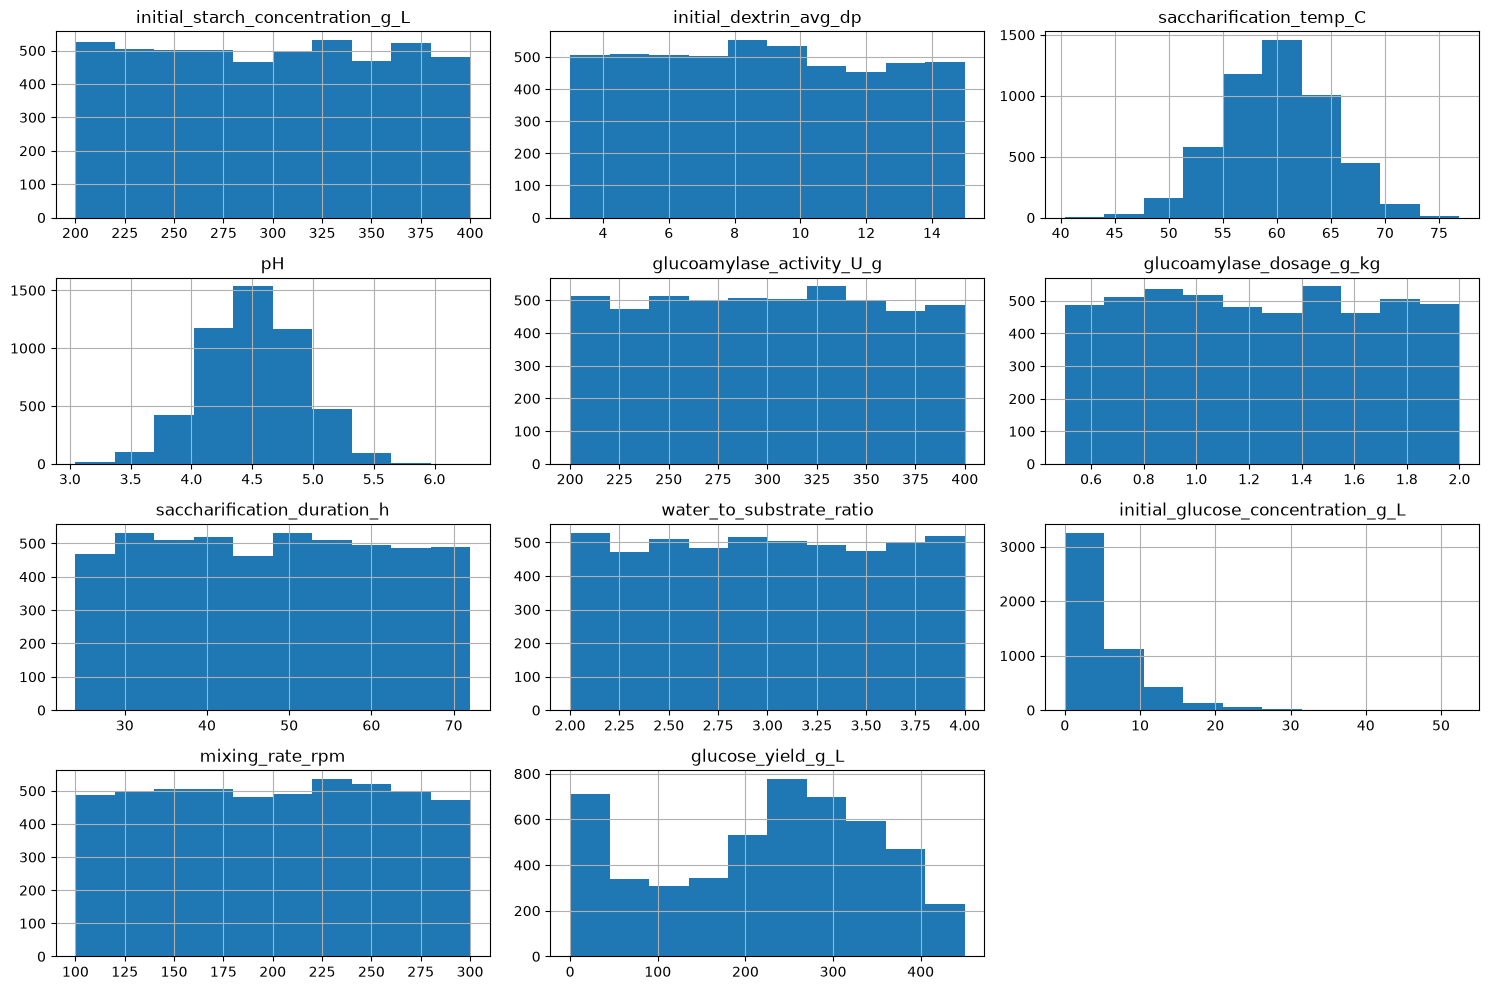

In [39]:
df.hist(figsize=(15, 10))
plt.tight_layout()
plt.show()

In [40]:
from pathlib import Path
print(Path.cwd())

c:\Users\HP\Documents\engine\glucose project\data


In [41]:
import sys
from pathlib import Path
import joblib
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import RAW_DATA_PATH
from src.loader import load_and_verify_data, split_to_three_way

raw_df = load_and_verify_data(RAW_DATA_PATH)

X_train, X_val, X_lockbox, y_train, y_val, y_lockbox = (
    split_to_three_way(raw_df)
)

MODEL_PATH = PROJECT_ROOT / "models" / "xgboost_production_model.joblib"
model = joblib.load(MODEL_PATH)

test_predictions = model.predict(X_lockbox)

In [42]:
import numpy as np
import pandas as pd

# Convert predictions and actual values into arrays
actual = np.asarray(y_lockbox).ravel()
predicted = np.asarray(test_predictions).ravel()

# Calculate prediction errors
errors = predicted - actual

# Find the worst over-prediction
worst_idx = np.argmax(errors)

worst_actual = actual[worst_idx]
worst_predicted = predicted[worst_idx]
worst_error = errors[worst_idx]

# Calculate relative error, avoiding division by zero
relative_error = (
    abs(worst_error / worst_actual) * 100
    if worst_actual != 0
    else np.nan
)

print(f"Actual glucose: {worst_actual:.2f} g/L")
print(f"Predicted glucose: {worst_predicted:.2f} g/L")
print(f"Over-prediction: {worst_error:.2f} g/L")
print(f"Relative error: {relative_error:.2f}%")

Actual glucose: 32.64 g/L
Predicted glucose: 203.75 g/L
Over-prediction: 171.11 g/L
Relative error: 524.22%


In [43]:
overprediction_df = pd.DataFrame({
    "Actual_g_L": actual,
    "Predicted_g_L": predicted,
    "Overprediction_g_L": errors,
})

overprediction_df = (
    overprediction_df[overprediction_df["Overprediction_g_L"] > 0]
    .sort_values("Overprediction_g_L", ascending=False)
    .copy()
)

overprediction_df["Relative_Error_%"] = (
    overprediction_df["Overprediction_g_L"]
    / overprediction_df["Actual_g_L"].replace(0, np.nan)
) * 100

display(overprediction_df.head(10))

,Actual_g_L,Predicted_g_L,Overprediction_g_L,Relative_Error_%
708,32.641197,203.753067,171.111870,524.220582
328,4.975574,114.952576,109.977001,2210.337855
496,0.614171,95.692314,95.078143,15480.722466
692,36.995412,129.249969,92.254558,249.367566
411,22.448529,109.806694,87.358165,389.148730
56,158.845196,232.361618,73.516422,46.281804
185,15.195146,83.711838,68.516691,450.911686
181,65.179296,133.235565,68.056269,104.413938
729,67.896058,135.294937,67.398879,99.267735
742,56.085746,122.447510,66.361764,118.321979


In [44]:
overprediction_analysis = pd.DataFrame({
    "Actual_g_L": actual,
    "Predicted_g_L": predicted,
})

overprediction_analysis["Error_g_L"] = (
    overprediction_analysis["Predicted_g_L"]
    - overprediction_analysis["Actual_g_L"]
)

overprediction_analysis["Concentration_Band"] = pd.cut(
    overprediction_analysis["Actual_g_L"],
    bins=[-np.inf, 100, 200, np.inf],
    labels=["Low (≤100)", "Medium (100–200)", "High (>200)"],
)

summary = overprediction_analysis.groupby(
    "Concentration_Band", observed=False
).apply(
    lambda group: pd.Series({
        "Samples": len(group),
        "RMSE_g_L": np.sqrt(np.mean(group["Error_g_L"] ** 2)),
        "Overprediction_Rate_%": (
            (group["Error_g_L"] > 0).mean() * 100
        ),
        "Mean_Error_g_L": group["Error_g_L"].mean(),
    }),
    include_groups=False,
)

display(summary.round(2))

,Samples,RMSE_g_L,Overprediction_Rate_%,Mean_Error_g_L
Concentration_Band,,,,
Low (≤100),160.0,36.36,88.12,23.52
Medium (100–200),131.0,27.52,74.05,14.10
High (>200),459.0,24.26,31.15,-11.20


In [45]:
import pandas as pd

def glucose_distribution(y, split_name):
    y = pd.Series(y)
    return pd.Series({
        "Split": split_name,
        "Samples": len(y),
        "Low (≤100 g/L)": (y <= 100).sum(),
        "Medium (100–200 g/L)": ((y > 100) & (y <= 200)).sum(),
        "High (>200 g/L)": (y > 200).sum(),
    })

distribution = pd.DataFrame([
    glucose_distribution(y_train, "Training"),
    glucose_distribution(y_val, "Validation"),
    glucose_distribution(y_lockbox, "Lockbox"),
]).set_index("Split")

display(distribution)

,Samples,Low (≤100 g/L),Medium (100–200 g/L),High (>200 g/L)
Split,,,,
Training,3499,778,533,2188
Validation,751,182,101,468
Lockbox,750,160,131,459


In [46]:
train_predictions = model.predict(X_train)

train_analysis = pd.DataFrame({
    "Actual_g_L": np.asarray(y_train).ravel(),
    "Predicted_g_L": np.asarray(train_predictions).ravel(),
})

train_analysis["Concentration_Band"] = pd.cut(
    train_analysis["Actual_g_L"],
    bins=[-np.inf, 100, 200, np.inf],
    labels=["Low (≤100)", "Medium (100–200)", "High (>200)"],
)

summary = train_analysis.groupby(
    "Concentration_Band", observed=False
).agg(
    Samples=("Actual_g_L", "size"),
    Mean_Actual=("Actual_g_L", "mean"),
    Mean_Predicted=("Predicted_g_L", "mean"),
)

summary["Mean_Error_g_L"] = (
    summary["Mean_Predicted"] - summary["Mean_Actual"]
)

display(summary.round(2))

,Samples,Mean_Actual,Mean_Predicted,Mean_Error_g_L
Concentration_Band,,,,
Low (≤100),778,36.84,58.200001,21.36
Medium (100–200),533,152.68,163.850006,11.17
High (>200),2188,305.87,296.649994,-9.21


In [47]:
def band_error_report(y_true, y_pred, split_name):
    df = pd.DataFrame({
        "Actual": np.asarray(y_true).ravel(),
        "Predicted": np.asarray(y_pred).ravel(),
    })

    df["Band"] = pd.cut(
        df["Actual"],
        bins=[-np.inf, 100, 200, np.inf],
        labels=["Low (≤100)", "Medium (100–200)", "High (>200)"],
    )

    df["Error"] = df["Predicted"] - df["Actual"]

    report = df.groupby("Band", observed=False).apply(
        lambda g: pd.Series({
            "Samples": len(g),
            "RMSE_g_L": np.sqrt(np.mean(g["Error"] ** 2)),
            "Mean_Error_g_L": g["Error"].mean(),
        }),
        include_groups=False,
    )

    report.insert(0, "Split", split_name)
    return report.reset_index()

train_predictions = model.predict(X_train)

comparison = pd.concat([
    band_error_report(y_train, train_predictions, "Training"),
    band_error_report(y_lockbox, test_predictions, "Lockbox"),
], ignore_index=True)

display(comparison.round(2))

,Band,Split,Samples,RMSE_g_L,Mean_Error_g_L
0,Low (≤100),Training,778.0,34.26,21.36
1,Medium (100–200),Training,533.0,28.95,11.17
2,High (>200),Training,2188.0,23.56,-9.21
3,Low (≤100),Lockbox,160.0,36.36,23.52
4,Medium (100–200),Lockbox,131.0,27.52,14.10
5,High (>200),Lockbox,459.0,24.26,-11.20


In [48]:

import sys
from pathlib import Path
import joblib
import numpy as np

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import RAW_DATA_PATH
from src.loader import load_and_verify_data, split_to_three_way
from src.evaluation import compute_yield_production_metrics

# Load dataset and recreate the original splits
raw_df = load_and_verify_data(RAW_DATA_PATH)
X_train, X_val, X_lockbox, y_train, y_val, y_lockbox = (
    split_to_three_way(raw_df)
)

# Load your standard-objective model
model_path = PROJECT_ROOT / "models copy" / "xgboost_production_model2.joblib"
xgb_regressor = joblib.load(model_path)

# Compare training and lockbox performance
train_predictions = xgb_regressor.predict(X_train)
test_predictions = xgb_regressor.predict(X_lockbox)

train_metrics = compute_yield_production_metrics(y_train, train_predictions)
test_metrics = compute_yield_production_metrics(y_lockbox, test_predictions)

print("Training RMSE:", train_metrics["Glucose_RMSE_g_L"])
print("Lockbox RMSE:", test_metrics["Glucose_RMSE_g_L"])


Training RMSE: 28.431870242621038
Lockbox RMSE: 29.547886833633335


In [49]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error

# Reconstruct the target formula from your actual generator
def reconstruct_glucose_yield(df):
    ph_effect = np.exp(-0.5 * ((df["pH"] - 4.5) / 0.3) ** 2)

    temp = df["saccharification_temp_C"]
    temp_effect = np.where(
        temp <= 60,
        np.exp(-0.5 * ((temp - 60) / 6) ** 2),
        np.exp(-0.5 * ((temp - 60) / 3) ** 2),
    )

    mixing = 0.7 + 0.3 * (1 - np.exp(-df["mixing_rate_rpm"] / 150))
    efficiency = ph_effect * temp_effect * mixing

    effective_enzyme = (
        df["glucoamylase_dosage_g_kg"]
        * df["glucoamylase_activity_U_g"]
    ) * efficiency

    dp_factor = 1 / (
        1 + 0.05 * (df["initial_dextrin_avg_dp"] - 3)
    )

    max_yield = df["initial_starch_concentration_g_L"] * 1.11
    k = 0.05 * effective_enzyme * dp_factor
    time_progression = 1 - np.exp(
        -k * df["saccharification_duration_h"] / 100
    )

    inhibition = 1 / (
        1 + 0.001 * df["initial_glucose_concentration_g_L"]
    )

    return np.clip(
        max_yield * time_progression * inhibition,
        0,
        max_yield,
    )


# Reconstruct theoretical yield for lockbox rows
formula_predictions = reconstruct_glucose_yield(X_lockbox)

actual = np.asarray(y_lockbox)
model_predictions = xgb_regressor.predict(X_lockbox)

results = pd.DataFrame({
    "Actual": actual,
    "Formula": formula_predictions,
    "Model": model_predictions,
})

results["Formula_Error"] = results["Formula"] - results["Actual"]
results["Model_Error"] = results["Model"] - results["Actual"]

print(
    "Formula RMSE:",
    np.sqrt(mean_squared_error(actual, formula_predictions)),
)
print(
    "Model RMSE:",
    np.sqrt(mean_squared_error(actual, model_predictions)),
)

print("\nLargest model errors:")
display(
    results.assign(
        Absolute_Error=results["Model_Error"].abs()
    )
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
)


Formula RMSE: 4.877941852230591
Model RMSE: 29.547886833633335

Largest model errors:


,Actual,Formula,Model,Formula_Error,Model_Error,Absolute_Error
3526,32.641197,32.770929,236.334778,0.129732,203.693581,203.693581
4152,4.975574,4.967020,163.895859,-0.008554,158.920285,158.920285
2298,26.523070,26.182462,139.516739,-0.340608,112.993669,112.993669
4252,60.630556,60.377532,168.799988,-0.253023,108.169432,108.169432
544,0.614171,0.646110,108.634422,0.031939,108.020251,108.020251
2416,62.822692,62.137346,167.346970,-0.685345,104.524278,104.524278
3197,22.448529,23.327097,125.476639,0.878569,103.028110,103.028110
3185,319.821910,311.531587,218.519821,-8.290322,-101.302089,101.302089
3641,56.085746,56.291286,154.336380,0.205541,98.250634,98.250634
3570,15.195146,15.286093,112.672440,0.090947,97.477293,97.477293


In [50]:

# Group lockbox errors by actual glucose yield
results["Yield_Range"] = pd.cut(
    results["Actual"],
    bins=[-np.inf, 100, 200, 300, np.inf],
    labels=["Low", "Medium", "High", "Very High"],
)

diagnostics = results.groupby(
    "Yield_Range", observed=False
).agg(
    Samples=("Actual", "count"),
    Mean_Actual=("Actual", "mean"),
    Mean_Predicted=("Model", "mean"),
    Mean_Error=("Model_Error", "mean"),
    RMSE=("Model_Error", lambda x: np.sqrt(np.mean(x**2))),
)

print(diagnostics)


             Samples  Mean_Actual  Mean_Predicted  Mean_Error       RMSE
Yield_Range                                                             
Low              160    38.509441       63.894215   25.384775  42.574319
Medium           131   159.076776      175.040878   15.964104  29.795272
High             256   250.069751      242.430893   -7.638856  20.652834
Very High        203   353.786319      341.000702  -12.785620  26.196129


In [51]:

# Training predictions
train_predictions = xgb_regressor.predict(X_train)

train_results = pd.DataFrame({
    "Actual": np.asarray(y_train),
    "Predicted": train_predictions,
})

train_results["Error"] = (
    train_results["Predicted"] - train_results["Actual"]
)

train_results["Yield_Range"] = pd.cut(
    train_results["Actual"],
    bins=[-np.inf, 100, 200, 300, np.inf],
    labels=["Low", "Medium", "High", "Very High"],
)

train_diagnostics = train_results.groupby(
    "Yield_Range", observed=False
).agg(
    Samples=("Actual", "count"),
    RMSE=("Error", lambda x: np.sqrt(np.mean(x**2))),
)

print("TRAINING PERFORMANCE")
print(train_diagnostics)

print("\nLOCKBOX PERFORMANCE")
print(diagnostics[["Samples", "RMSE"]])


TRAINING PERFORMANCE
             Samples       RMSE
Yield_Range                    
Low              778  38.841676
Medium           533  30.524743
High            1083  22.059378
Very High       1105  23.898500

LOCKBOX PERFORMANCE
             Samples       RMSE
Yield_Range                    
Low              160  42.574319
Medium           131  29.795272
High             256  20.652834
Very High        203  26.196129


In [52]:
print("Training samples:", len(X_train))
print("Lockbox samples:", len(X_lockbox))

print("Model training RMSE:", np.sqrt(np.mean(
    (xgb_regressor.predict(X_train) - np.asarray(y_train)) ** 2
)))

print("Lockbox RMSE:", np.sqrt(np.mean(
    (xgb_regressor.predict(X_lockbox) - np.asarray(y_lockbox)) ** 2
)))

print("Model parameters:")
print(xgb_regressor.get_params())

Training samples: 3499
Lockbox samples: 750
Model training RMSE: 28.431870242621038
Lockbox RMSE: 29.547886833633335
Model parameters:
{'objective': None, 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 0.8, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': None, 'feature_types': None, 'feature_weights': None, 'gamma': 0.5, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.05, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 4, 'max_leaves': None, 'min_child_weight': 3, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 1000, 'n_jobs': -1, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': 1, 'reg_lambda': 5, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': 0.8, 'tree_method': None, 'validate_parameters'

In [53]:
# Compare feature distributions between training and lockbox
comparison = pd.DataFrame({
    "Train_Mean": X_train.mean(),
    "Lockbox_Mean": X_lockbox.mean(),
    "Train_Std": X_train.std(),
    "Lockbox_Std": X_lockbox.std(),
})

comparison["Mean_Difference"] = (
    comparison["Lockbox_Mean"] - comparison["Train_Mean"]
).abs()

print(comparison.sort_values("Mean_Difference", ascending=False).round(3))

                                   Train_Mean  Lockbox_Mean  Train_Std  \
initial_starch_concentration_g_L      300.010       297.240     58.063   
glucoamylase_activity_U_g             299.132       301.221     56.859   
mixing_rate_rpm                       199.084       200.669     57.291   
saccharification_duration_h            48.096        47.531     13.889   
saccharification_temp_C                59.931        60.239      4.891   
initial_glucose_concentration_g_L       5.027         4.729      5.110   
initial_dextrin_avg_dp                  8.903         8.839      3.432   
water_to_substrate_ratio                2.994         3.013      0.584   
glucoamylase_dosage_g_kg                1.249         1.253      0.430   
pH                                      4.510         4.514      0.408   

                                   Lockbox_Std  Mean_Difference  
initial_starch_concentration_g_L        57.468            2.770  
glucoamylase_activity_U_g               57.166       

In [54]:
# Combine lockbox inputs and prediction errors
error_analysis = X_lockbox.copy()
error_analysis["Actual"] = np.asarray(y_lockbox)
error_analysis["Predicted"] = xgb_regressor.predict(X_lockbox)
error_analysis["Absolute_Error"] = (
    error_analysis["Predicted"] - error_analysis["Actual"]
).abs()

# Compare feature values for the worst 20% of errors vs the rest
error_analysis["Worst_Error"] = (
    error_analysis["Absolute_Error"] >= error_analysis["Absolute_Error"].quantile(0.8)
)

print(
    error_analysis.groupby("Worst_Error").mean(numeric_only=True).T.round(2)
)

Worst_Error                         False   True 
initial_starch_concentration_g_L   292.11  317.75
initial_dextrin_avg_dp               8.80    9.01
saccharification_temp_C             60.06   60.94
pH                                   4.50    4.56
glucoamylase_activity_U_g          299.60  307.69
glucoamylase_dosage_g_kg             1.24    1.32
saccharification_duration_h         47.66   47.01
water_to_substrate_ratio             3.01    3.04
initial_glucose_concentration_g_L    4.60    5.25
mixing_rate_rpm                    200.61  200.93
Actual                             225.26  184.56
Predicted                          225.15  195.65
Absolute_Error                      13.21   52.69


In [55]:
print("Current dataset size:", len(raw_df))
print("Current training size:", len(X_train))
print("Current lockbox size:", len(X_lockbox))

Current dataset size: 5000
Current training size: 3499
Current lockbox size: 750


In [56]:
print("Dataset:", len(raw_df))
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Lockbox:", len(X_lockbox))

Dataset: 5000
Training: 3499
Validation: 751
Lockbox: 750
